In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv('../../data/processed/reg-szn/player_data_merged.csv')

In [12]:
# Grab PCA from EDA
scores = pd.read_csv('../../data/processed/reg-szn/pca_scores.csv')
pc_cols = [c for c in scores.columns if c.startswith('PC')]
X_pca = scores[pc_cols]

In [13]:
X_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
0,3.778066,-0.349854,-0.589746,1.478032,-0.651029,1.088562,-2.612462,-0.347348,-0.549560
1,7.520921,1.873264,1.926614,-0.162369,-2.431934,-2.818607,-0.574351,-0.635994,2.388491
2,0.843790,2.349329,-2.580658,0.866174,1.414942,0.009035,-1.797470,-0.059307,0.513140
3,0.851342,-4.303886,0.031474,-0.004824,-1.529060,-0.285084,0.869003,0.469281,0.753829
4,0.533900,-0.006509,-1.920955,0.397194,1.273786,0.398333,-2.181924,-1.395958,-0.213939
...,...,...,...,...,...,...,...,...,...
374,-0.773809,-2.516434,0.091153,2.662449,1.445579,1.146829,1.996446,0.696388,-0.210413
375,-0.770680,-2.218398,-1.222529,-0.476710,-1.467270,2.323122,0.336205,-1.090459,-1.129623
376,1.064942,-0.320775,-0.227026,-2.600626,0.652084,2.350101,-0.607599,-0.780002,-0.522006
377,0.626354,-2.745133,-1.318089,-1.817483,0.638522,0.214692,-0.694771,-0.945577,0.127529


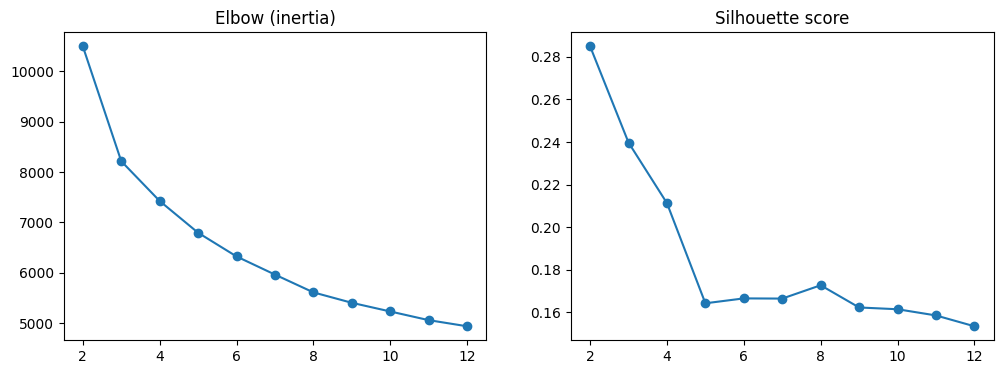

In [ ]:
# Pick k: elbow + silhouette
ks = range(2, 13)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_pca)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_pca, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker='o'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(ks, sils, marker='o');     ax[1].set_title('Silhouette score')
plt.show()


# k = 8 seems to be the most ideal.

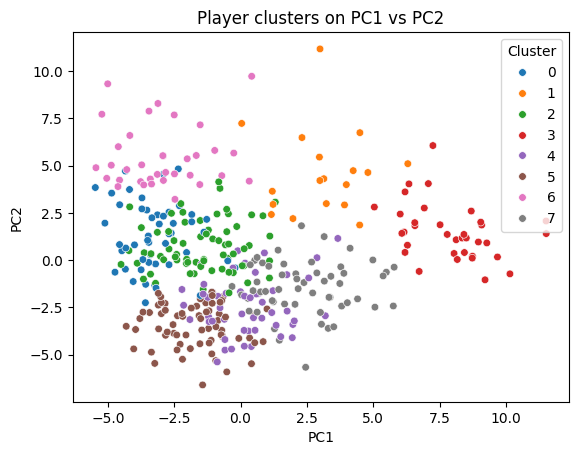

0 ['Jose Alvarado', 'Cole Anthony', 'Lonzo Ball', 'Jamaree Bouyea', 'Bub Carrington', 'Devin Carter', 'Walter Clayton', 'Isaiah Collier']
1 ['Giannis Antetokounmpo', 'Scottie Barnes', 'Anthony Davis', 'Joel Embiid', 'Chet Holmgren', 'Jaren Jackson Jr.', 'Evan Mobley', 'Jusuf Nurkić']
2 ['Bam Adebayo', 'Nickeil Alexander-Walker', 'Grayson Allen', 'Desmond Bane', 'RJ Barrett', 'Saddiq Bey', 'Anthony Black', 'Miles Bridges']
3 ['Steven Adams', 'Jarrett Allen', 'Deandre Ayton', 'Marvin Bagley III', 'Goga Bitadze', 'Adem Bona', 'Clint Capela', 'Dylan Cardwell']
4 ['Kyle Anderson', 'Bruce Brown', 'Alex Caruso', 'Sidy Cissoko', 'Jaylen Clark', 'Nique Clifford', 'Bilal Coulibaly', 'Dyson Daniels']
5 ['Ochai Agbaji', 'Ace Bailey', 'Harrison Barnes', 'Jamison Battle', 'Nicolas Batum', 'Christian Braun', 'Mikal Bridges', 'Toumani Camara']
6 ['Deni Avdija', 'LaMelo Ball', 'Paolo Banchero', 'Devin Booker', 'Jaylen Brown', 'Jalen Brunson', 'Jimmy Butler', 'Stephon Castle']
7 ['Precious Achiuwa', 'Sa

In [ ]:
k = 8 
km = KMeans(n_clusters=k, n_init=20, random_state=42)
scores['Cluster'] = km.fit_predict(X_pca)

sns.scatterplot(data=scores, x='PC1', y='PC2', hue='Cluster', palette='tab10', s=30)
plt.title('Player clusters on PC1 vs PC2')
plt.show()

for c, grp in scores.groupby('Cluster'):
    print(c, grp['Player'].head(8).tolist())
